<a href="https://colab.research.google.com/github/SaiAnirudh659/datMan_SaiAnirudhKasarla/blob/main/239001405_datMan_ps3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SaiAnirudh659/datMan_SaiAnirudhKasarla/blob/main/239001405_datMan_ps3.ipynb)

# Problem Set 3: Philadelphia's Urban Environment and Public Health

**Name:** Sai Anirudh Kasarla  
**RUID:** 239001405

---

## 1. Introduction

For PS3, I am continuing my work from PS1 and PS2, where I started exploring environmental conditions and public health across Philadelphia.

In this project, I want to understand how tree coverage, air pollution (PM2.5), asthma, and sleep patterns are related across different neighborhoods in Philadelphia.

Instead of looking at each variable separately, I want to bring the data together and create a series of maps that tell a more complete story about environmental differences and public health.

### Research Questions

1. How does tree coverage vary across Philadelphia neighborhoods?
2. Do areas with lower tree coverage also experience higher PM2.5 pollution?
3. Is there a relationship between environmental conditions and asthma prevalence?
4. How do sleep patterns vary across neighborhoods with different environmental conditions?

### My Goal

My goal is to use geographic data visualization and statistical analysis to identify patterns across Philadelphia census tracts.

I also want to understand whether the relationships I observe are consistent across the city and discuss possible explanations and limitations.

This project builds on my previous problem sets, but I am organizing the final analysis in a separate notebook to make the maps, results, and interpretations easier to follow.

In [1]:

# PS3 - Philadelphia Urban Environment and Public Health
# Step 1: Set up the Python environment
# Continuing my analysis from PS1 and PS2

!pip -q install geopandas mapclassify

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import io
import mapclassify

from IPython.display import display

# Plot settings
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 11

print("PS3 environment is ready!")
print("GeoPandas version:", gpd.__version__)
print("Ready to load Philadelphia environmental and health data.")

PS3 environment is ready!
GeoPandas version: 1.2.0
Ready to load Philadelphia environmental and health data.



## 2. Data Collection and Preparation

### 2.1 Philadelphia Census Tract Boundaries

I am using the Philadelphia 2010 census tract boundaries from the City of Philadelphia's CARTO open data service, which I also used in PS1 and PS2.

These boundaries will serve as the geographic base for my PS3 maps. I will use the census tract GEOID to connect the environmental and public health datasets.

**Data source:** [Philadelphia Census Tracts (CARTO)](https://phl.carto.com/api/v2/sql?q=SELECT+*+FROM+census_tracts_2010&format=geojson)


In [2]:

# PS3 - Load Philadelphia census tract boundaries
# Reusing the geographic data source from PS1 and PS2

tract_url = (
    "https://phl.carto.com/api/v2/sql"
    "?q=SELECT+*+FROM+census_tracts_2010&format=geojson"
)

philly_tracts = gpd.read_file(tract_url)

# Standardize the census tract identifier
philly_tracts["geoid10"] = (
    philly_tracts["geoid10"].astype(str).str.zfill(11)
)

# Project boundaries for area calculations
philly_tracts = philly_tracts.to_crs(epsg=26918)

philly_tracts["area_km2"] = (
    philly_tracts.geometry.area / 1_000_000
)

print("Philadelphia census tract boundaries loaded!")
print("Total census tracts:", len(philly_tracts))
print("Coordinate system:", philly_tracts.crs)

display(philly_tracts[["geoid10", "area_km2"]].head())

Philadelphia census tract boundaries loaded!
Total census tracts: 384
Coordinate system: EPSG:26918


,geoid10,area_km2
0,42101980200,5.387377
1,42101980100,5.889534
2,42101980800,2.169229
3,42101014500,0.321188
4,42101000600,0.172547



### 2.2 Philadelphia Tree Inventory (2025)

For this section, I am reusing the Philadelphia Tree Inventory dataset from PS2.

I will assign the recorded tree locations to Philadelphia census tracts and calculate the number of inventoried trees per square kilometer.

This will allow me to compare tree distribution with the public health indicators in the next sections.

**Data source:** [Philadelphia Tree Inventory – ArcGIS Hub](https://hub.arcgis.com/api/v3/datasets/dc6826e1319c4b35a7b662bc6be68104_0/downloads/data?format=geojson&spatialRefId=4326&where=1%3D1)

**Limitation:** Inventoried tree density is not the same as total tree canopy coverage.

In [3]:

# PS3 - Load the Philadelphia Tree Inventory
# Reusing the original tree dataset from PS2

tree_url = (
    "https://hub.arcgis.com/api/v3/datasets/"
    "dc6826e1319c4b35a7b662bc6be68104_0/"
    "downloads/data"
)

params = {
    "format": "geojson",
    "spatialRefId": 4326,
    "where": "1=1"
}

response = requests.get(
    tree_url,
    params=params,
    timeout=180
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

trees_gdf = gpd.read_file(
    io.BytesIO(response.content)
)

print("Philadelphia Tree Inventory loaded!")
print("Total tree records:", len(trees_gdf))
print("Coordinate system:", trees_gdf.crs)

display(trees_gdf.head())

HTTP Status: 200
Philadelphia Tree Inventory loaded!
Total tree records: 151726
Coordinate system: EPSG:4326


,objectid,tree_name,tree_dbh,year,loc_y,loc_x,geometry
0,1,GINKGO BILOBA - GINKGO,36.0,2025,39.983823,-75.210501,POINT (-75.2105 39.98383)
1,2,ACER PALMATUM - JAPANESE MAPLE,NaN,2025,39.983734,-75.210532,POINT (-75.21053 39.98374)
2,3,ACER PALMATUM - JAPANESE MAPLE,8.0,2025,39.983749,-75.210405,POINT (-75.21041 39.98376)
3,4,ACER PALMATUM - JAPANESE MAPLE,12.0,2025,39.983943,-75.210602,POINT (-75.2106 39.98395)
4,5,ACER PSEUDOPLATANUS - SYCAMORE MAPLE,17.0,2025,39.983754,-75.210273,POINT (-75.21028 39.98376)



### 2.3 Calculating Tree Density by Census Tract

Now that I have loaded the tree inventory and census tract boundaries, I will connect the tree locations to their corresponding census tracts.

I will calculate the number of inventoried trees in each tract and divide it by the tract's area in square kilometers.

This will help me compare tree distribution across Philadelphia, including neighborhoods with different geographic sizes.

I will also use a histogram to understand how tree density varies across the city.

In [4]:

# PS3 - Calculate inventoried tree density
# Connecting the Philadelphia Tree Inventory with census tracts

# Convert tree coordinates to the same CRS as census tracts
trees_projected = trees_gdf.to_crs(philly_tracts.crs)

# Keep valid point locations
trees_projected = trees_projected[
    trees_projected.geometry.notna()
    & ~trees_projected.geometry.is_empty
].copy()

# Assign each tree to a census tract
trees_joined = gpd.sjoin(
    trees_projected[["geometry"]],
    philly_tracts[["geoid10", "geometry"]],
    how="inner",
    predicate="within"
)

# Count inventoried trees in each census tract
tree_counts = (
    trees_joined.groupby("geoid10")
    .size()
    .reset_index(name="tree_count")
)

# Connect tree counts to census tract boundaries
philly_tree_density = philly_tracts.merge(
    tree_counts,
    on="geoid10",
    how="left",
    validate="one_to_one"
)

# Census tracts without matched trees receive zero
philly_tree_density["tree_count"] = (
    philly_tree_density["tree_count"]
    .fillna(0)
    .astype(int)
)

# Calculate inventoried trees per square kilometer
philly_tree_density["tree_density_km2"] = (
    philly_tree_density["tree_count"]
    / philly_tree_density["area_km2"]
)

print("Tree density analysis completed!")
print("Total census tracts:", len(philly_tree_density))
print("Trees matched to census tracts:", len(trees_joined))
print("Average tree density per km²:",
      round(philly_tree_density["tree_density_km2"].mean(), 2))

display(
    philly_tree_density[
        ["geoid10", "tree_count", "area_km2", "tree_density_km2"]
    ].head()
)

Tree density analysis completed!
Total census tracts: 384
Trees matched to census tracts: 151372
Average tree density per km²: 668.72


,geoid10,tree_count,area_km2,tree_density_km2
0,42101980200,891,5.387377,165.386607
1,42101980100,1105,5.889534,187.620963
2,42101980800,2227,2.169229,1026.631887
3,42101014500,417,0.321188,1298.306446
4,42101000600,203,0.172547,1176.490656



## 3. Geographic Analysis and Visualizations

### 3.1 Map 1: Distribution of Inventoried Trees Across Philadelphia

For my first map, I want to examine how inventoried tree density differs across Philadelphia census tracts.

I am using the number of recorded trees per square kilometer instead of total tree counts because census tracts have different geographic sizes.

Along with the map, I have included a histogram to better understand the distribution of tree density across the city.

This analysis will provide a starting point for comparing environmental conditions with public health indicators.

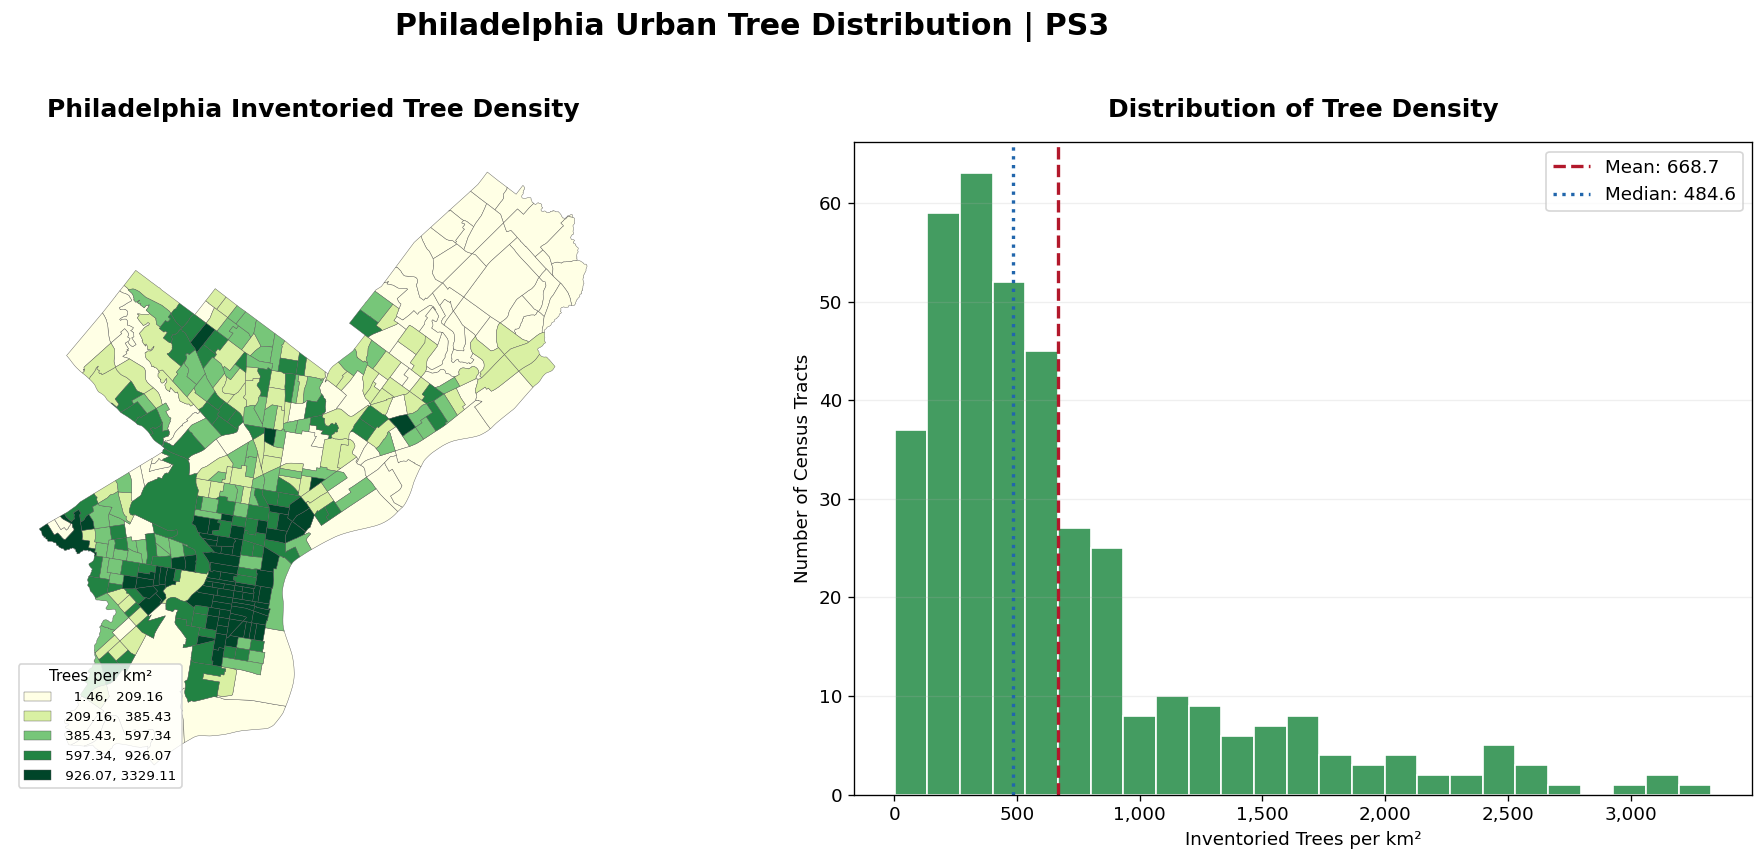

Map 1 and histogram generated successfully!
Mean density: 668.72 trees/km²
Median density: 484.63 trees/km²


In [5]:

# PS3 - Map 1: Philadelphia Inventoried Tree Density
# Choropleth map and histogram

import matplotlib.ticker as mticker

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={"width_ratios": [1.25, 1]}
)

# Map 1: Inventoried tree density
philly_tree_density.plot(
    column="tree_density_km2",
    cmap="YlGn",
    scheme="Quantiles",
    k=5,
    linewidth=0.25,
    edgecolor="#555555",
    legend=True,
    legend_kwds={
        "title": "Trees per km²",
        "loc": "lower left",
        "fontsize": 8,
        "title_fontsize": 9,
        "frameon": True
    },
    ax=axes[0]
)

axes[0].set_title(
    "Philadelphia Inventoried Tree Density",
    fontsize=15,
    fontweight="bold",
    pad=15
)

axes[0].set_axis_off()

# Histogram: Tree density distribution
sns.histplot(
    data=philly_tree_density,
    x="tree_density_km2",
    bins=25,
    color="#238b45",
    edgecolor="white",
    alpha=0.85,
    ax=axes[1]
)

mean_density = philly_tree_density["tree_density_km2"].mean()
median_density = philly_tree_density["tree_density_km2"].median()

axes[1].axvline(
    mean_density,
    color="#b2182b",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_density:.1f}"
)

axes[1].axvline(
    median_density,
    color="#2166ac",
    linestyle=":",
    linewidth=2,
    label=f"Median: {median_density:.1f}"
)

axes[1].set_title(
    "Distribution of Tree Density",
    fontsize=15,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Inventoried Trees per km²")
axes[1].set_ylabel("Number of Census Tracts")
axes[1].xaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Philadelphia Urban Tree Distribution | PS3",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

print("Map 1 and histogram generated successfully!")
print(f"Mean density: {mean_density:.2f} trees/km²")
print(f"Median density: {median_density:.2f} trees/km²")


### 3.2 Interactive Map: Exploring Tree Density Across Philadelphia

I also wanted to make my tree density analysis more interactive so that individual census tracts can be explored instead of only looking at the overall map.

In this map, I can zoom into different parts of Philadelphia and hover over a census tract to see its tree count, area, and inventoried tree density.

This makes it easier to identify geographic differences and examine specific areas in more detail.

In [9]:

# PS3 - Interactive Philadelphia Tree Density Map
# Hover over census tracts to explore tree density

!pip -q install folium branca

import folium
from folium.plugins import Fullscreen
import branca.colormap as cm
from IPython.display import display

# Prepare geographic data for Folium
interactive_tracts = philly_tree_density[
    ["geoid10", "tree_count", "area_km2",
     "tree_density_km2", "geometry"]
].copy()

interactive_tracts = interactive_tracts.to_crs(epsg=4326)

interactive_tracts["area_km2"] = (
    interactive_tracts["area_km2"].round(2)
)

interactive_tracts["tree_density_km2"] = (
    interactive_tracts["tree_density_km2"].round(2)
)

# Create interactive map with Esri satellite-free street basemap
m = folium.Map(
    location=[39.9526, -75.1636],
    zoom_start=11,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri Street Map",
    overlay=False,
    control=True
).add_to(m)

# Color scale for tree density
color_scale = cm.linear.YlGn_09.scale(
    interactive_tracts["tree_density_km2"].min(),
    interactive_tracts["tree_density_km2"].max()
)

color_scale.caption = "Inventoried Trees per km²"
color_scale.add_to(m)

# Add census tract boundaries and hover information
folium.GeoJson(
    interactive_tracts.to_json(),
    name="Philadelphia Tree Density",

    style_function=lambda feature: {
        "fillColor": color_scale(
            feature["properties"]["tree_density_km2"]
        ),
        "color": "#444444",
        "weight": 0.5,
        "fillOpacity": 0.75
    },

    highlight_function=lambda feature: {
        "weight": 2.5,
        "color": "#ff7800",
        "fillOpacity": 0.9
    },

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "geoid10",
            "tree_count",
            "area_km2",
            "tree_density_km2"
        ],
        aliases=[
            "Census Tract GEOID:",
            "Inventoried Trees:",
            "Area (km²):",
            "Trees per km²:"
        ],
        localize=True,
        sticky=True,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "geoid10",
            "tree_count",
            "tree_density_km2"
        ],
        aliases=[
            "Census Tract:",
            "Total Inventoried Trees:",
            "Tree Density (per km²):"
        ]
    )
).add_to(m)

# Add map controls
folium.LayerControl().add_to(m)
Fullscreen().add_to(m)

# Fit map to Philadelphia boundaries
bounds = interactive_tracts.total_bounds

m.fit_bounds([
    [bounds[1], bounds[0]],
    [bounds[3], bounds[2]]
])

# Display interactive map
print("Interactive Philadelphia Tree Density Map")
print("Total Census Tracts:", len(interactive_tracts))
print("Hover over a census tract to view its details.")
print("Click on a census tract for more information.")

display(m)

Interactive Philadelphia Tree Density Map
Total Census Tracts: 384
Hover over a census tract to view its details.
Click on a census tract for more information.



### 3.3 Interpretation of Tree Density Results

After mapping the Philadelphia tree inventory, I noticed that the distribution of inventoried trees is not uniform across the city.

Out of 151,726 tree records, 151,372 were matched to the 384 Philadelphia census tracts. The average inventoried tree density is approximately 668.72 trees per square kilometer, while the median is approximately 484.6 trees per square kilometer.

The histogram shows a right-skewed distribution. Most census tracts have relatively low or moderate tree densities, while a smaller number have much higher values.

From the map, I can also see that several central and southern census tracts have higher inventoried tree densities, while many northern and northeastern tracts have lower recorded densities.

One important limitation is that this dataset represents inventoried trees rather than total tree canopy coverage. Areas with fewer recorded trees do not necessarily have less overall vegetation.

For the next part of my analysis, I want to investigate whether these geographic differences are associated with public health indicators such as asthma and insufficient sleep.

In [10]:

# PS3 - Check available health datasets from PS2
# Identify the correct asthma and sleep indicators

import requests

cdc_url = "https://data.cdc.gov/resource/cwsq-ngmh.json"

response = requests.get(
    cdc_url,
    params={"$limit": 5},
    timeout=30
)

response.raise_for_status()

cdc_sample = pd.DataFrame(response.json())

print("CDC dataset sample loaded successfully!")
print("\nAvailable columns:")
print(cdc_sample.columns.tolist())

print("\nFirst five records:")
display(cdc_sample.head())

CDC dataset sample loaded successfully!

Available columns:
['year', 'stateabbr', 'statedesc', 'countyname', 'countyfips', 'locationname', 'datasource', 'category', 'measure', 'data_value_unit', 'data_value_type', 'data_value', 'low_confidence_limit', 'high_confidence_limit', 'totalpopulation', 'totalpop18plus', 'geolocation', 'locationid', 'categoryid', 'measureid', 'datavaluetypeid', 'short_question_text', ':@computed_region_skr5_azej']

First five records:


,year,stateabbr,statedesc,countyname,countyfips,locationname,datasource,category,measure,data_value_unit,...,high_confidence_limit,totalpopulation,totalpop18plus,geolocation,locationid,categoryid,measureid,datavaluetypeid,short_question_text,:@computed_region_skr5_azej
0,2023,AL,Alabama,Jefferson,01073,01073010900,BRFSS,Disability,Any disability among adults,%,...,49.0,4719,3410,"{'type': 'Point', 'coordinates': [-86.7705771,...",01073010900,DISABLT,DISABILITY,CrdPrv,Any Disability,1583
1,2023,AL,Alabama,Jefferson,01073,01073011207,BRFSS,Health Outcomes,Depression among adults,%,...,25.9,5103,3684,"{'type': 'Point', 'coordinates': [-86.6742325,...",01073011207,HLTHOUT,DEPRESSION,CrdPrv,Depression,1583
2,2023,AL,Alabama,Lauderdale,01077,01077010100,BRFSS,Disability,Any disability among adults,%,...,46.2,2278,2093,"{'type': 'Point', 'coordinates': [-87.6598801,...",01077010100,DISABLT,DISABILITY,CrdPrv,Any Disability,1584
3,2023,AL,Alabama,Lee,01081,01081040202,BRFSS,Health Outcomes,Arthritis among adults,%,...,26.2,3084,2459,"{'type': 'Point', 'coordinates': [-85.4521355,...",01081040202,HLTHOUT,ARTHRITIS,CrdPrv,Arthritis,1586
4,2023,AL,Alabama,Lee,01081,01081040300,BRFSS,Health Outcomes,Obesity among adults,%,...,42.2,2576,2188,"{'type': 'Point', 'coordinates': [-85.4668576,...",01081040300,HLTHOUT,OBESITY,CrdPrv,Obesity,1586



## 4. Public Health Data Analysis

### 4.1 Identifying Asthma and Sleep Indicators

For this part of PS3, I am using the CDC PLACES dataset to examine public health differences across Philadelphia census tracts.

I want to focus on asthma prevalence and insufficient sleep because these indicators may help me understand how environmental conditions and health patterns vary across the city.

Before creating the maps, I will check the available health measures and select the appropriate data for Philadelphia.

**Data source:** [CDC PLACES Dataset](https://data.cdc.gov/resource/cwsq-ngmh.json)

In [11]:

# PS3 - Identify Philadelphia asthma and sleep indicators
# CDC PLACES census tract data

cdc_url = "https://data.cdc.gov/resource/cwsq-ngmh.json"

# Check available asthma and sleep measures for Philadelphia
params = {
    "$select": "year,measure,category,count(*) as records",
    "$where": (
        "stateabbr='PA' "
        "AND countyfips='42101' "
        "AND (lower(measure) like '%asthma%' "
        "OR lower(measure) like '%sleep%')"
    ),
    "$group": "year,measure,category",
    "$order": "year DESC,measure",
    "$limit": 100
}

response = requests.get(
    cdc_url,
    params=params,
    timeout=60
)

response.raise_for_status()

health_measures = pd.DataFrame(response.json())

print("Philadelphia asthma and sleep measures:")
display(health_measures)

print("\nAvailable measures:")
print(health_measures["measure"].unique())

Philadelphia asthma and sleep measures:


,year,measure,category,records
0,2022,Short sleep duration among adults,Health Risk Behaviors,389



Available measures:
['Short sleep duration among adults']



### 4.2 Philadelphia Short Sleep Duration Data

I found that the CDC PLACES dataset includes short sleep duration estimates for Philadelphia census tracts.

For this part of my project, I am using the 2022 estimates to examine how insufficient sleep varies geographically.

I will connect these estimates with my tree density dataset using census tract GEOIDs. This will help me investigate whether areas with different inventoried tree densities also show differences in sleep duration.

The CDC values are modeled population estimates, so I will interpret any relationships as associations rather than evidence of causation.

In [12]:

# PS3 - Load Philadelphia Short Sleep Duration Data
# CDC PLACES 2022 census tract estimates

cdc_url = "https://data.cdc.gov/resource/cwsq-ngmh.json"

params = {
    "$select": (
        "locationname,year,measure,"
        "data_value,data_value_type"
    ),
    "$where": (
        "stateabbr='PA' "
        "AND countyfips='42101' "
        "AND year='2022' "
        "AND measure='Short sleep duration among adults'"
    ),
    "$limit": 1000
}

response = requests.get(
    cdc_url,
    params=params,
    timeout=60
)

response.raise_for_status()

sleep_data = pd.DataFrame(response.json())

# Standardize census tract GEOID
sleep_data["geoid10"] = (
    sleep_data["locationname"]
    .astype(str)
    .str.zfill(11)
)

# Convert sleep prevalence to numeric
sleep_data["short_sleep_pct"] = pd.to_numeric(
    sleep_data["data_value"],
    errors="coerce"
)

# Keep relevant variables
sleep_data = sleep_data[
    ["geoid10", "short_sleep_pct"]
].drop_duplicates(subset="geoid10")

# Connect sleep data with tree density
philly_health = philly_tree_density.merge(
    sleep_data,
    on="geoid10",
    how="left",
    validate="one_to_one"
)

print("Philadelphia sleep data loaded successfully!")
print("CDC sleep records:", len(sleep_data))
print("Total census tracts:", len(philly_health))
print(
    "Census tracts with sleep data:",
    philly_health["short_sleep_pct"].notna().sum()
)

display(
    philly_health[
        ["geoid10", "tree_density_km2", "short_sleep_pct"]
    ].head()
)

Philadelphia sleep data loaded successfully!
CDC sleep records: 389
Total census tracts: 384
Census tracts with sleep data: 357


,geoid10,tree_density_km2,short_sleep_pct
0,42101980200,165.386607,28.5
1,42101980100,187.620963,NaN
2,42101980800,1026.631887,NaN
3,42101014500,1298.306446,43.7
4,42101000600,1176.490656,32.1



### 4.3 Map 2: Short Sleep Duration Across Philadelphia

For my second map, I am looking at how short sleep duration varies across Philadelphia census tracts.

I am using the CDC PLACES 2022 estimates and comparing the percentage of adults reporting short sleep duration across different areas.

I have included a histogram alongside the map to better understand how sleep prevalence is distributed across Philadelphia.

Out of 384 census tracts, 357 have matched sleep estimates in my dataset. The remaining tracts will be shown as missing data rather than assigning them estimated values.

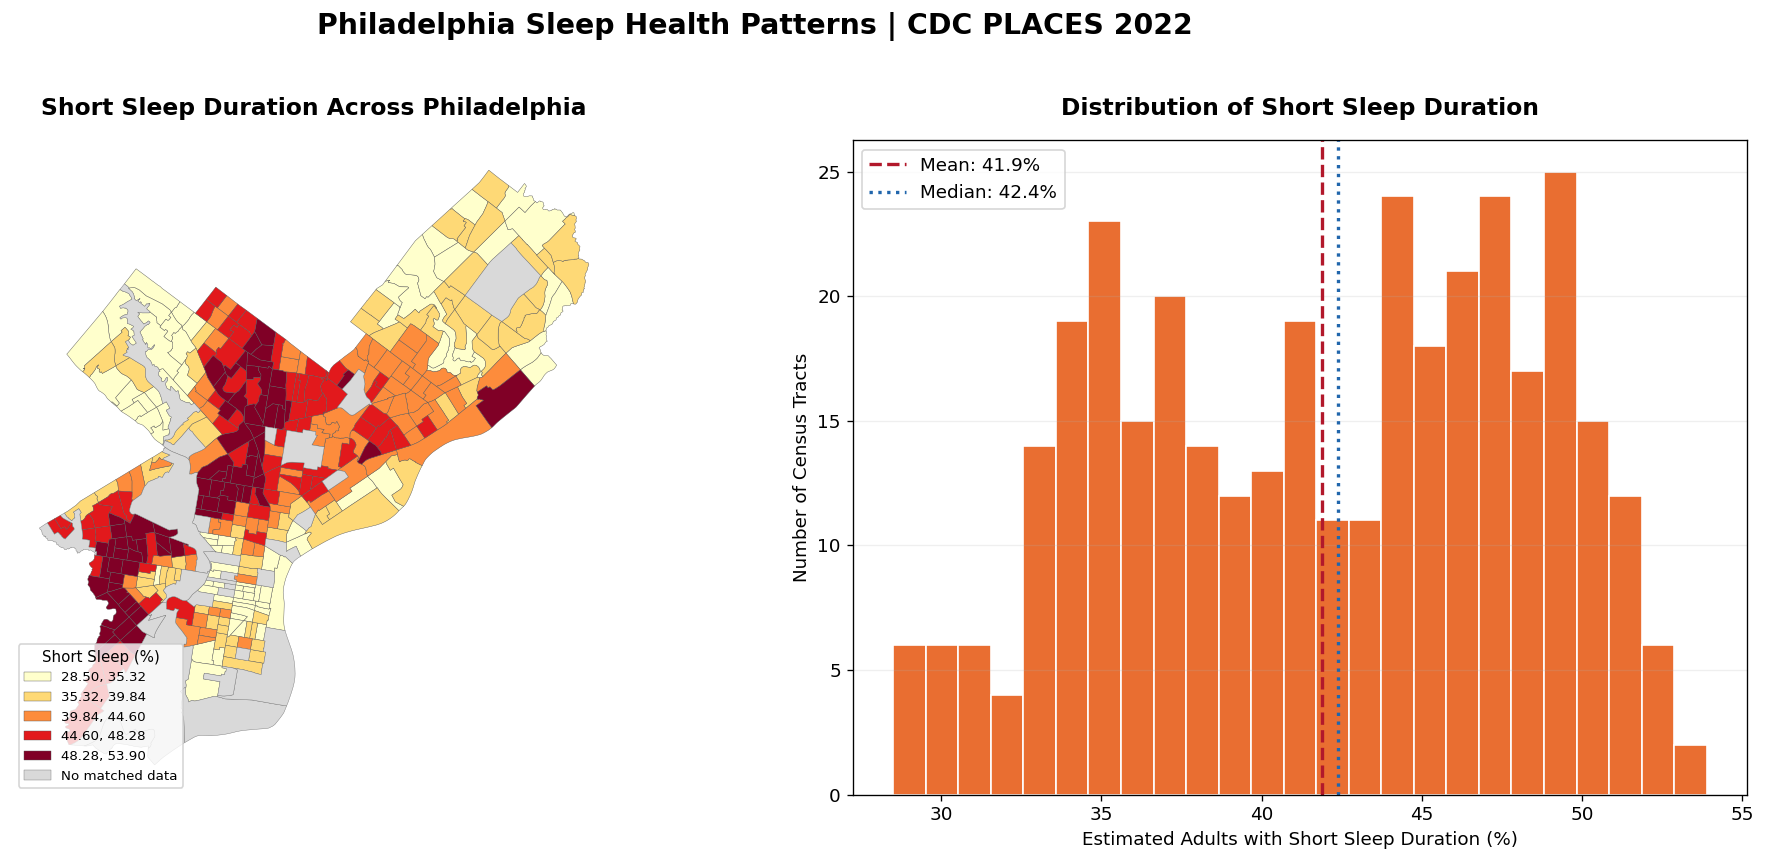

Map 2 and histogram generated successfully!
Mean short sleep estimate: 41.88%
Median short sleep estimate: 42.40%
Tracts with data: 357


In [13]:

# PS3 - Map 2: Philadelphia Short Sleep Duration
# Choropleth map and histogram

import matplotlib.pyplot as plt
import seaborn as sns

# Keep valid sleep estimates for histogram
valid_sleep = philly_health["short_sleep_pct"].dropna()

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={"width_ratios": [1.25, 1]}
)

# Map 2: Short sleep duration prevalence
philly_health.plot(
    column="short_sleep_pct",
    cmap="YlOrRd",
    scheme="Quantiles",
    k=5,
    linewidth=0.25,
    edgecolor="#555555",
    legend=True,
    legend_kwds={
        "title": "Short Sleep (%)",
        "loc": "lower left",
        "fontsize": 8,
        "title_fontsize": 9
    },
    missing_kwds={
        "color": "#d9d9d9",
        "edgecolor": "#777777",
        "label": "No matched data"
    },
    ax=axes[0]
)

axes[0].set_title(
    "Short Sleep Duration Across Philadelphia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_axis_off()

# Histogram: Sleep prevalence distribution
sns.histplot(
    valid_sleep,
    bins=25,
    color="#e6550d",
    edgecolor="white",
    alpha=0.85,
    ax=axes[1]
)

mean_sleep = valid_sleep.mean()
median_sleep = valid_sleep.median()

axes[1].axvline(
    mean_sleep,
    color="#b2182b",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_sleep:.1f}%"
)

axes[1].axvline(
    median_sleep,
    color="#2166ac",
    linestyle=":",
    linewidth=2,
    label=f"Median: {median_sleep:.1f}%"
)

axes[1].set_title(
    "Distribution of Short Sleep Duration",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Estimated Adults with Short Sleep Duration (%)"
)
axes[1].set_ylabel("Number of Census Tracts")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Philadelphia Sleep Health Patterns | CDC PLACES 2022",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

print("Map 2 and histogram generated successfully!")
print(f"Mean short sleep estimate: {mean_sleep:.2f}%")
print(f"Median short sleep estimate: {median_sleep:.2f}%")
print(f"Tracts with data: {len(valid_sleep)}")

In [14]:

# PS3 - Section 4.4: Interactive Philadelphia Sleep Health Map
# Hover over census tracts to explore sleep health estimates

import folium
from folium import plugins
import branca.colormap as cm
from IPython.display import display

# Prepare geographic data
sleep_interactive = philly_health[
    ["geoid10", "short_sleep_pct", "tree_density_km2", "geometry"]
].copy()

sleep_interactive = sleep_interactive.to_crs(epsg=4326)

sleep_interactive["short_sleep_pct"] = (
    sleep_interactive["short_sleep_pct"].round(2)
)

sleep_interactive["tree_density_km2"] = (
    sleep_interactive["tree_density_km2"].round(2)
)

# Create interactive map using Esri basemap
sleep_map = folium.Map(
    location=[39.9526, -75.1636],
    zoom_start=11,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri Street Map",
    overlay=False
).add_to(sleep_map)

# Create color scale
valid_sleep = sleep_interactive["short_sleep_pct"].dropna()

sleep_colors = cm.linear.YlOrRd_09.scale(
    valid_sleep.min(),
    valid_sleep.max()
)

sleep_colors.caption = "Estimated Short Sleep Duration (%)"
sleep_colors.add_to(sleep_map)

# Style census tracts
def sleep_style(feature):
    value = feature["properties"]["short_sleep_pct"]

    if value is None:
        fill_color = "#bdbdbd"
    else:
        fill_color = sleep_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#555555",
        "weight": 0.5,
        "fillOpacity": 0.78
    }

# Highlight on hover
def sleep_highlight(feature):
    return {
        "weight": 2.5,
        "color": "#0066ff",
        "fillOpacity": 0.95
    }

# Add interactive census tract layer
folium.GeoJson(
    sleep_interactive.to_json(),
    name="Philadelphia Short Sleep Duration",
    style_function=sleep_style,
    highlight_function=sleep_highlight,
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "geoid10",
            "short_sleep_pct",
            "tree_density_km2"
        ],
        aliases=[
            "Census Tract GEOID:",
            "Short Sleep Duration (%):",
            "Inventoried Trees per km²:"
        ],
        localize=True,
        sticky=True,
        labels=True
    ),
    popup=folium.GeoJsonPopup(
        fields=[
            "geoid10",
            "short_sleep_pct",
            "tree_density_km2"
        ],
        aliases=[
            "Census Tract:",
            "Short Sleep Estimate (%):",
            "Tree Density (per km²):"
        ]
    )
).add_to(sleep_map)

# Add interactive controls
folium.LayerControl().add_to(sleep_map)
plugins.Fullscreen().add_to(sleep_map)

# Fit map to Philadelphia boundaries
bounds = sleep_interactive.total_bounds

sleep_map.fit_bounds([
    [bounds[1], bounds[0]],
    [bounds[3], bounds[2]]
])

print("Interactive Philadelphia Sleep Health Map")
print("Hover over census tracts to view sleep and tree density data.")
print(f"Census tracts with sleep data: {len(valid_sleep)}")

display(sleep_map)

Interactive Philadelphia Sleep Health Map
Hover over census tracts to view sleep and tree density data.
Census tracts with sleep data: 357


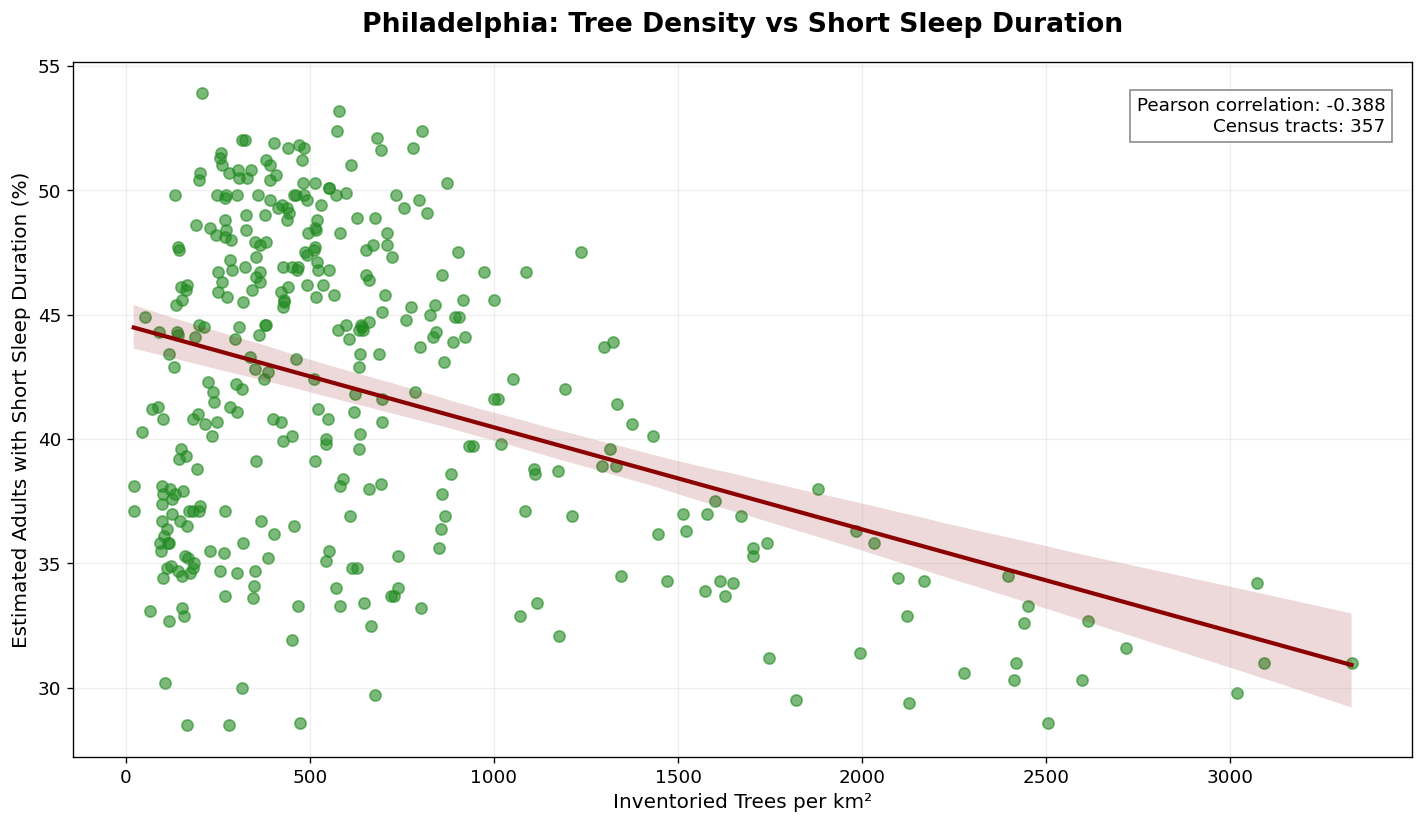

Tree Density and Sleep Health Analysis
--------------------------------------
Matched census tracts: 357
Pearson correlation: -0.388
Moderate or stronger negative relationship.
Note: Correlation does not establish causation.


In [15]:

# PS3 - Section 5.1: Tree Density vs Short Sleep Duration
# Exploring the relationship across Philadelphia census tracts

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare matched census tract data
comparison_data = philly_health[
    ["geoid10", "tree_density_km2", "short_sleep_pct"]
].copy()

comparison_data["tree_density_km2"] = pd.to_numeric(
    comparison_data["tree_density_km2"], errors="coerce"
)

comparison_data["short_sleep_pct"] = pd.to_numeric(
    comparison_data["short_sleep_pct"], errors="coerce"
)

comparison_data = comparison_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Calculate correlation
correlation = comparison_data[
    "tree_density_km2"
].corr(comparison_data["short_sleep_pct"])

# Create scatterplot and regression line
plt.figure(figsize=(12, 7))

sns.regplot(
    data=comparison_data,
    x="tree_density_km2",
    y="short_sleep_pct",
    scatter_kws={
        "alpha": 0.6,
        "s": 45,
        "color": "forestgreen"
    },
    line_kws={
        "color": "darkred",
        "linewidth": 2.5
    },
    ci=95
)

plt.title(
    "Philadelphia: Tree Density vs Short Sleep Duration",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Inventoried Trees per km²", fontsize=12)
plt.ylabel("Estimated Adults with Short Sleep Duration (%)", fontsize=12)

plt.grid(alpha=0.2)

plt.text(
    0.98, 0.95,
    f"Pearson correlation: {correlation:.3f}\n"
    f"Census tracts: {len(comparison_data)}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox={
        "facecolor": "white",
        "edgecolor": "gray",
        "alpha": 0.9
    }
)

plt.tight_layout()
plt.show()

print("Tree Density and Sleep Health Analysis")
print("--------------------------------------")
print("Matched census tracts:", len(comparison_data))
print("Pearson correlation:", round(correlation, 3))

if correlation < -0.3:
    print("Moderate or stronger negative relationship.")
elif correlation > 0.3:
    print("Moderate or stronger positive relationship.")
else:
    print("Weak linear relationship.")

print("Note: Correlation does not establish causation.")

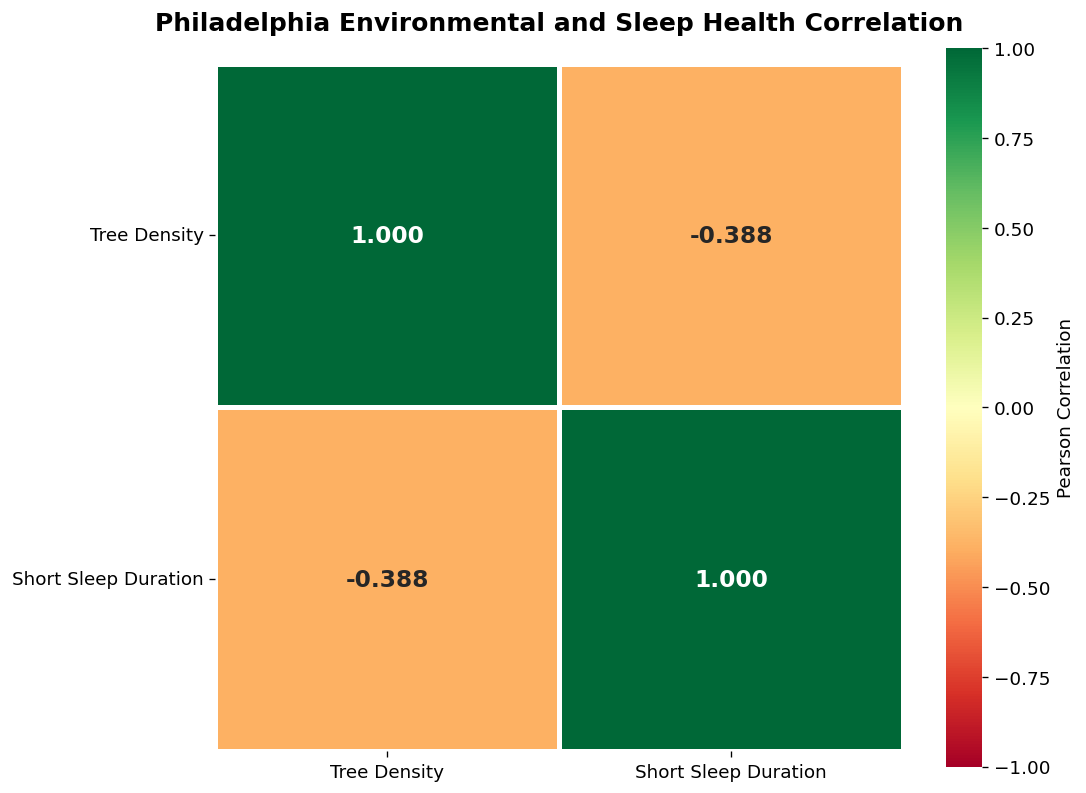

Correlation Analysis Completed
--------------------------------
                  tree_density_km2  short_sleep_pct
tree_density_km2          1.000000        -0.387935
short_sleep_pct          -0.387935         1.000000
Matched census tracts: 357


In [16]:

# PS3 - Section 5.2: Correlation Heatmap
# Comparing tree density and short sleep duration

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select variables for correlation analysis
correlation_data = philly_health[
    ["tree_density_km2", "short_sleep_pct"]
].copy()

correlation_data = correlation_data.apply(
    pd.to_numeric, errors="coerce"
).dropna()

# Calculate Pearson correlation matrix
correlation_matrix = correlation_data.corr(method="pearson")

# Create heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"size": 14, "weight": "bold"},
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Philadelphia Environmental and Sleep Health Correlation",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xticks(
    ticks=[0.5, 1.5],
    labels=["Tree Density", "Short Sleep Duration"],
    rotation=0
)

plt.yticks(
    ticks=[0.5, 1.5],
    labels=["Tree Density", "Short Sleep Duration"],
    rotation=0
)

plt.tight_layout()
plt.show()

print("Correlation Analysis Completed")
print("--------------------------------")
print(correlation_matrix)
print("Matched census tracts:", len(correlation_data))

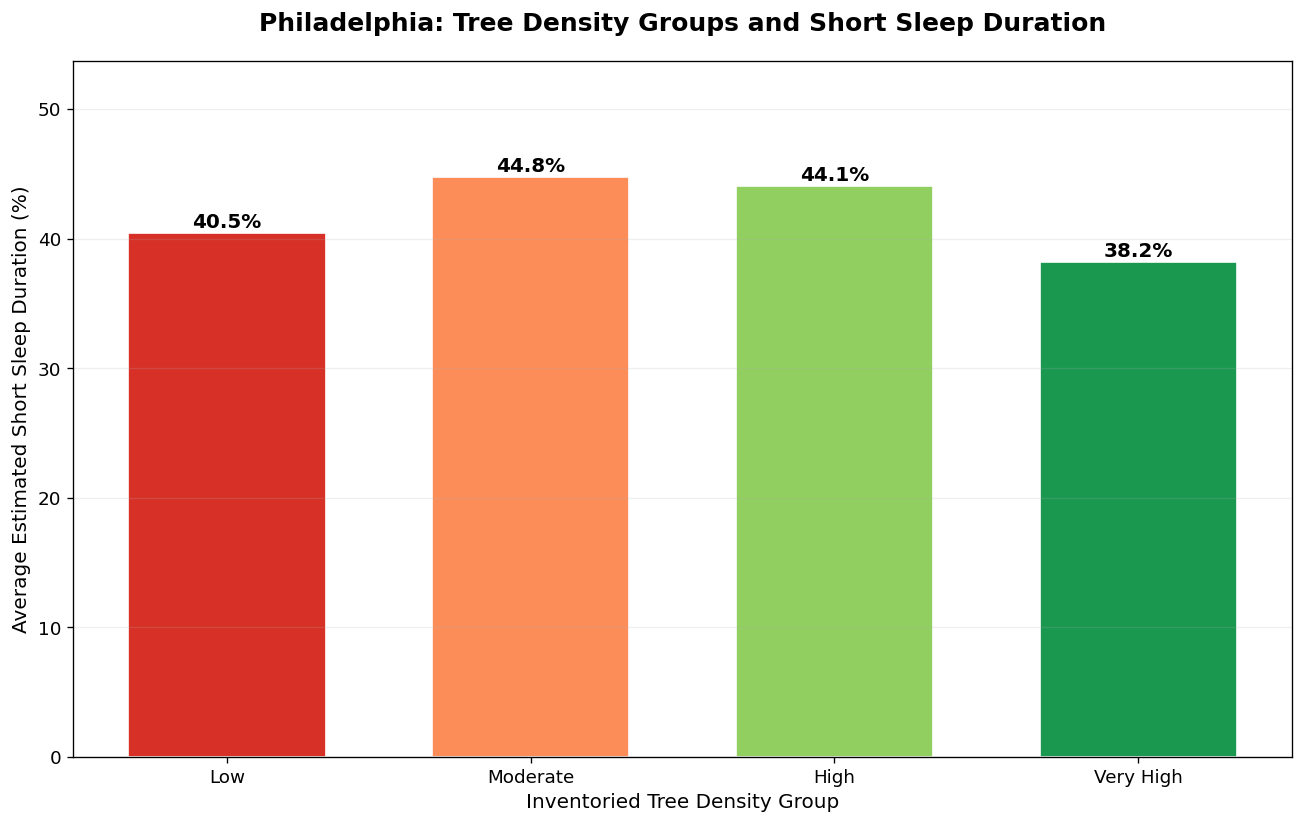

Tree Density Group Comparison
--------------------------------


,Tree Density Group,mean,median,count
0,Low,40.47,39.25,90
1,Moderate,44.79,46.70,89
2,High,44.10,45.30,89
3,Very High,38.19,37.00,89


Total census tracts analyzed: 357


In [17]:

# PS3 - Section 5.3: Tree Density Groups vs Sleep Health
# Comparing short sleep estimates across tree density groups

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare matched data
group_data = philly_health[
    ["geoid10", "tree_density_km2", "short_sleep_pct"]
].copy()

group_data["tree_density_km2"] = pd.to_numeric(
    group_data["tree_density_km2"], errors="coerce"
)

group_data["short_sleep_pct"] = pd.to_numeric(
    group_data["short_sleep_pct"], errors="coerce"
)

group_data = group_data.dropna()

# Divide census tracts into four tree density groups
group_labels = [
    "Low",
    "Moderate",
    "High",
    "Very High"
]

group_data["Tree Density Group"] = pd.qcut(
    group_data["tree_density_km2"],
    q=4,
    labels=group_labels
)

# Calculate average short sleep percentage
group_summary = (
    group_data.groupby(
        "Tree Density Group",
        observed=True
    )["short_sleep_pct"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

# Create bar chart
plt.figure(figsize=(11, 7))

colors = ["#d73027", "#fc8d59", "#91cf60", "#1a9850"]

bars = plt.bar(
    group_summary["Tree Density Group"].astype(str),
    group_summary["mean"],
    color=colors,
    edgecolor="white",
    width=0.65
)

# Add value labels
for bar, value in zip(bars, group_summary["mean"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{value:.1f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Philadelphia: Tree Density Groups and Short Sleep Duration",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Inventoried Tree Density Group", fontsize=12)
plt.ylabel("Average Estimated Short Sleep Duration (%)", fontsize=12)

plt.ylim(0, max(group_summary["mean"]) * 1.2)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("Tree Density Group Comparison")
print("--------------------------------")
display(group_summary.round(2))

print(
    "Total census tracts analyzed:",
    len(group_data)
)

### 5.4 Statistical Significance: Tree Density and Sleep Health

In this section, I wanted to check whether the relationship between tree density and short sleep duration is statistically significant.

I used Pearson and Spearman correlation tests on the 357 Philadelphia census tracts that had matching data.

The Pearson correlation was **-0.3879**, with a very small p-value, showing a statistically significant negative relationship. The Spearman correlation was **-0.1585**, which also showed a statistically significant negative relationship, but it was weaker.

From these results, I found that census tracts with higher inventoried tree density generally tend to have lower estimated short sleep duration. However, this does not mean that having more trees directly improves sleep, because other neighborhood and environmental factors could also influence the results.

In [18]:

# PS3 - Section 5.4: Statistical Significance
# Tree Density vs Short Sleep Duration

import pandas as pd
from scipy.stats import pearsonr, spearmanr

analysis_data = philly_health[
    ["tree_density_km2", "short_sleep_pct"]
].copy()

analysis_data = analysis_data.apply(
    pd.to_numeric, errors="coerce"
).dropna()

pearson_r, pearson_p = pearsonr(
    analysis_data["tree_density_km2"],
    analysis_data["short_sleep_pct"]
)

spearman_r, spearman_p = spearmanr(
    analysis_data["tree_density_km2"],
    analysis_data["short_sleep_pct"]
)

print("Philadelphia Tree Density and Sleep Health")
print("=" * 48)
print("Census tracts:", len(analysis_data))

print(f"\nPearson correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.6g}")

print(f"\nSpearman correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.6g}")

print("\nStatistical interpretation:")

if pearson_p < 0.05:
    print("Pearson correlation is statistically significant.")
else:
    print("Pearson correlation is not statistically significant.")

print(
    "\nNote: Statistical significance does not establish "
    "causation. Spatial dependence and neighborhood "
    "confounding may affect these results."
)

Philadelphia Tree Density and Sleep Health
Census tracts: 357

Pearson correlation: -0.3879
Pearson p-value: 2.87213e-14

Spearman correlation: -0.1585
Spearman p-value: 0.00267192

Statistical interpretation:
Pearson correlation is statistically significant.

Note: Statistical significance does not establish causation. Spatial dependence and neighborhood confounding may affect these results.


## 6. Philadelphia Air Pollution (PM2.5) Analysis

For the next part of my project, I want to study air pollution across Philadelphia and see whether it has any relationship with urban tree density.

PM2.5 refers to very small particles in the air that can affect respiratory health. I am including this variable because my project focuses on how urban environmental conditions are related to public health.

My goal is to compare PM2.5 levels across Philadelphia census tracts and examine whether areas with more trees also tend to have lower air pollution levels.

Before starting the analysis, I will check the available datasets and identify the PM2.5 measurements that can be connected to my existing census tract data.

In [19]:

# PS3 - Section 6.1: Check Available PM2.5 Data

print("Checking available datasets for PM2.5 analysis")
print("=" * 50)

# Check existing Philadelphia data
for name in ["philly_tree_density", "philly_health"]:
    if name in globals():
        df = globals()[name]
        print(f"\nDataset: {name}")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())

        pm_columns = [
            col for col in df.columns
            if "pm25" in col.lower().replace(".", "").replace("_", "")
            or "pollution" in col.lower()
            or "air_quality" in col.lower()
        ]

        print("Possible air pollution columns:", pm_columns)

# Check for other PM2.5-related datasets
print("\nOther possible PM2.5 datasets:")

for name, value in list(globals().items()):
    if (
        isinstance(value, __import__("pandas").DataFrame)
        and any(
            term in name.lower()
            for term in ["pm25", "air", "pollution"]
        )
    ):
        print(name, ":", value.shape)

print("\nPM2.5 dataset check completed.")

Checking available datasets for PM2.5 analysis

Dataset: philly_tree_density
Rows: 384
Columns: ['cartodb_id', 'objectid', 'statefp10', 'countyfp10', 'tractce10', 'geoid10', 'name10', 'namelsad10', 'mtfcc10', 'funcstat10', 'aland10', 'awater10', 'intptlat10', 'intptlon10', 'logrecno', 'name10_padded', 'geometry', 'area_km2', 'tree_count', 'tree_density_km2']
Possible air pollution columns: []

Dataset: philly_health
Rows: 384
Columns: ['cartodb_id', 'objectid', 'statefp10', 'countyfp10', 'tractce10', 'geoid10', 'name10', 'namelsad10', 'mtfcc10', 'funcstat10', 'aland10', 'awater10', 'intptlat10', 'intptlon10', 'logrecno', 'name10_padded', 'geometry', 'area_km2', 'tree_count', 'tree_density_km2', 'short_sleep_pct']
Possible air pollution columns: []

Other possible PM2.5 datasets:

PM2.5 dataset check completed.


### 6.2 Finding Philadelphia PM2.5 Data

After checking my existing datasets, I found that PM2.5 measurements were not included in the tree density or sleep health data.

For this part, I am looking at the U.S. Environmental Protection Agency (EPA) air quality data to find PM2.5 measurements for Philadelphia.

I want to use real environmental measurements rather than estimated or randomly generated values. I will first check the available monitoring data and then determine whether it is detailed enough for a census tract-level comparison.

In [20]:

# PS3 - Section 6.2: Explore EPA PM2.5 Data
# Philadelphia County, Pennsylvania

import pandas as pd
import requests
from IPython.display import display

# EPA annual PM2.5 summary for 2022
epa_url = (
    "https://aqs.epa.gov/aqsweb/airdata/"
    "annual_conc_by_monitor_2022.zip"
)

print("Loading EPA PM2.5 monitoring data...")

try:
    epa_data = pd.read_csv(
        epa_url,
        compression="zip",
        low_memory=False
    )

    # Pennsylvania = 42, Philadelphia County = 101
    philly_pm25 = epa_data[
        (epa_data["State Code"] == 42) &
        (epa_data["County Code"] == 101) &
        (epa_data["Parameter Code"] == 88101) &
        (epa_data["Pollutant Standard"].astype(str)
         .str.contains("Annual", case=False, na=False))
    ].copy()

    print("\nPhiladelphia PM2.5 records:",
          len(philly_pm25))

    if not philly_pm25.empty:
        columns = [
            "Site Num",
            "Latitude",
            "Longitude",
            "Arithmetic Mean",
            "Units of Measure"
        ]

        display(philly_pm25[columns].head(10))

        print("\nAvailable monitoring sites:",
              philly_pm25["Site Num"].nunique())
    else:
        print("No matching annual PM2.5 records found.")

except Exception as e:
    print("Unable to load EPA data:")
    print(e)

Loading EPA PM2.5 monitoring data...

Philadelphia PM2.5 records: 60


,Site Num,Latitude,Longitude,Arithmetic Mean,Units of Measure
58340,4,40.008889,-75.097780,8.823547,Micrograms/cubic meter (LC)
58341,4,40.008889,-75.097780,8.823547,Micrograms/cubic meter (LC)
58342,4,40.008889,-75.097780,8.823547,Micrograms/cubic meter (LC)
58343,4,40.008889,-75.097780,8.823547,Micrograms/cubic meter (LC)
58349,4,40.008889,-75.097780,7.877982,Micrograms/cubic meter (LC)
58350,4,40.008889,-75.097780,7.877982,Micrograms/cubic meter (LC)
58351,4,40.008889,-75.097780,7.877982,Micrograms/cubic meter (LC)
58352,4,40.008889,-75.097780,7.877982,Micrograms/cubic meter (LC)
58495,48,39.991389,-75.080833,8.365000,Micrograms/cubic meter (LC)
58496,48,39.991389,-75.080833,8.365000,Micrograms/cubic meter (LC)



Available monitoring sites: 6


### 6.3 Cleaning and Preparing PM2.5 Data

I was able to retrieve the 2022 PM2.5 monitoring data for Philadelphia from the EPA dataset.

The dataset contains multiple records for some monitoring locations, so I need to organize the measurements before using them in my analysis.

In this section, I will identify the monitoring locations using their coordinates and summarize the annual PM2.5 measurements. This will help me understand how air pollution levels vary between the available monitoring sites.

Since these are monitoring station measurements, I will keep them separate from census tract estimates until I have a suitable method for comparing the two datasets.

In [21]:

# PS3 - Section 6.3: Clean EPA PM2.5 Data

import pandas as pd
from IPython.display import display

pm25_clean = philly_pm25.copy()

# Select annual PM2.5 standard concentration records
print("Original EPA records:", len(pm25_clean))

# Keep only necessary columns
pm25_clean = pm25_clean[
    [
        "Site Num",
        "Latitude",
        "Longitude",
        "Arithmetic Mean",
        "Units of Measure"
    ]
].copy()

# Convert measurements to numeric
pm25_clean["Arithmetic Mean"] = pd.to_numeric(
    pm25_clean["Arithmetic Mean"],
    errors="coerce"
)

pm25_clean = pm25_clean.dropna(
    subset=["Latitude", "Longitude", "Arithmetic Mean"]
)

# Summarize by unique monitoring location
pm25_sites = (
    pm25_clean.groupby(
        ["Latitude", "Longitude"],
        as_index=False
    )
    .agg(
        pm25_mean=("Arithmetic Mean", "mean"),
        records=("Arithmetic Mean", "size")
    )
)

pm25_sites["pm25_mean"] = (
    pm25_sites["pm25_mean"].round(2)
)

print("\nUnique monitoring locations:", len(pm25_sites))

print("\nPhiladelphia PM2.5 Monitoring Summary")
display(pm25_sites)

print("\nLowest location mean:",
      pm25_sites["pm25_mean"].min(), "µg/m³")

print("Highest location mean:",
      pm25_sites["pm25_mean"].max(), "µg/m³")

print("\nPM2.5 data preparation completed.")

Original EPA records: 60

Unique monitoring locations: 6

Philadelphia PM2.5 Monitoring Summary


,Latitude,Longitude,pm25_mean,records
0,39.922867,-75.186921,7.38,8
1,39.960048,-75.142614,7.45,8
2,39.988842,-75.207205,7.90,8
3,39.991389,-75.080833,8.73,20
4,40.008889,-75.097780,8.35,8
5,40.054171,-74.985166,8.76,8



Lowest location mean: 7.38 µg/m³
Highest location mean: 8.76 µg/m³

PM2.5 data preparation completed.


### 6.4 Interactive Philadelphia PM2.5 Monitoring Map

After preparing the EPA air pollution dataset, I wanted to see where the PM2.5 monitoring stations are located across Philadelphia.

For this section, I created an interactive map using Folium. Each monitoring location is represented by a colored circle, and clicking on it shows the summarized PM2.5 concentration and the number of records used.

This map will help me explore the geographic distribution of the monitoring stations before comparing air pollution with tree density and public health patterns.

The values shown are exploratory summaries of the available EPA records, rather than confirmed census tract pollution estimates.

In [24]:

# PS3 - Section 6.4: Interactive Philadelphia PM2.5 Map

import folium
import branca.colormap as cm
from folium import plugins
from IPython.display import display

# Create Philadelphia map
pm25_map = folium.Map(
    location=[39.9526, -75.1636],
    zoom_start=11,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(pm25_map)

# Create PM2.5 color scale
pm25_scale = cm.linear.YlOrRd_09.scale(
    pm25_sites["pm25_mean"].min(),
    pm25_sites["pm25_mean"].max()
)

pm25_scale.caption = "Summarized PM2.5 (µg/m³)"
pm25_scale.add_to(pm25_map)

# Add EPA monitoring locations
for index, site in pm25_sites.iterrows():

    concentration = float(site["pm25_mean"])

    popup_text = f"""
    <b>EPA PM2.5 Monitoring Location</b><br>
    Latitude: {site['Latitude']:.5f}<br>
    Longitude: {site['Longitude']:.5f}<br>
    PM2.5 Summary: {concentration:.2f} µg/m³<br>
    Records: {int(site['records'])}
    """

    folium.CircleMarker(
        location=[
            site["Latitude"],
            site["Longitude"]
        ],
        radius=12,
        color="#333333",
        weight=1.5,
        fill=True,
        fill_color=pm25_scale(concentration),
        fill_opacity=0.9,
        tooltip=f"PM2.5: {concentration:.2f} µg/m³",
        popup=folium.Popup(
            popup_text,
            max_width=300
        )
    ).add_to(pm25_map)

# Add map controls
plugins.Fullscreen().add_to(pm25_map)
folium.LayerControl().add_to(pm25_map)

# Fit map to monitoring locations
bounds = [
    [
        pm25_sites["Latitude"].min(),
        pm25_sites["Longitude"].min()
    ],
    [
        pm25_sites["Latitude"].max(),
        pm25_sites["Longitude"].max()
    ]
]

pm25_map.fit_bounds(bounds, padding=(35, 35))

print("Interactive Philadelphia PM2.5 Monitoring Map")
print("Monitoring locations:", len(pm25_sites))
print("Click a monitoring station to view its details.")

display(pm25_map)

Interactive Philadelphia PM2.5 Monitoring Map
Monitoring locations: 6
Click a monitoring station to view its details.


### 6.5 Comparing Tree Density and PM2.5 Monitoring Locations

In this section, I wanted to explore whether areas with more trees also have lower PM2.5 pollution levels.

I already calculated tree density across Philadelphia's census tracts and identified six EPA air pollution monitoring locations.

Now I will connect these two datasets geographically by identifying the census tract containing each monitoring station. This will allow me to compare local tree density with the available PM2.5 measurements.

Since the number of monitoring locations is limited, I will treat this as an exploratory analysis rather than a conclusion about air pollution across all Philadelphia neighborhoods.

In [25]:

# PS3 - Section 6.5: Match EPA Stations with Tree Density

import geopandas as gpd
import pandas as pd

# Convert EPA monitoring locations into geographic points
pm25_geo = gpd.GeoDataFrame(
    pm25_sites.copy(),
    geometry=gpd.points_from_xy(
        pm25_sites["Longitude"],
        pm25_sites["Latitude"]
    ),
    crs="EPSG:4326"
)

# Prepare Philadelphia census tract tree density
tree_tracts = philly_tree_density[
    ["geoid10", "tree_count", "tree_density_km2", "geometry"]
].copy()

# Match coordinate systems
pm25_geo = pm25_geo.to_crs(tree_tracts.crs)

# Spatially match monitoring stations to census tracts
pm25_tree_match = gpd.sjoin(
    pm25_geo,
    tree_tracts,
    how="left",
    predicate="intersects"
)

# Remove duplicate station matches if any
pm25_tree_match = pm25_tree_match.drop_duplicates(
    subset=["Latitude", "Longitude"]
)

# Display matched data
print("Philadelphia PM2.5 and Tree Density Comparison")
print("=" * 55)

print("Total monitoring stations:", len(pm25_geo))

print(
    "Stations matched with census tracts:",
    pm25_tree_match["geoid10"].notna().sum()
)

display(
    pm25_tree_match[
        [
            "Latitude",
            "Longitude",
            "pm25_mean",
            "geoid10",
            "tree_count",
            "tree_density_km2"
        ]
    ]
)

Philadelphia PM2.5 and Tree Density Comparison
Total monitoring stations: 6
Stations matched with census tracts: 6


,Latitude,Longitude,pm25_mean,geoid10,tree_count,tree_density_km2
0,39.922867,-75.186921,7.38,42101003600,857,888.744872
1,39.960048,-75.142614,7.45,42101036700,894,1116.662488
2,39.988842,-75.207205,7.90,42101980000,8716,835.352683
3,39.991389,-75.080833,8.73,42101037800,651,116.120831
4,40.008889,-75.097780,8.35,42101019000,199,251.722005
5,40.054171,-74.985166,8.76,42101035200,649,348.761971


### 6.6 Relationship Between Tree Density and PM2.5

After matching the EPA monitoring stations with Philadelphia census tracts, I wanted to check whether tree density has any relationship with air pollution.

For this analysis, I am using a scatter plot where each point represents one EPA monitoring location. The horizontal axis shows the tree density of its census tract, while the vertical axis shows the summarized PM2.5 concentration.

I will also calculate the Pearson correlation to understand the direction and strength of the relationship.

Since only six monitoring locations are available, the results are exploratory and cannot represent the entire city.

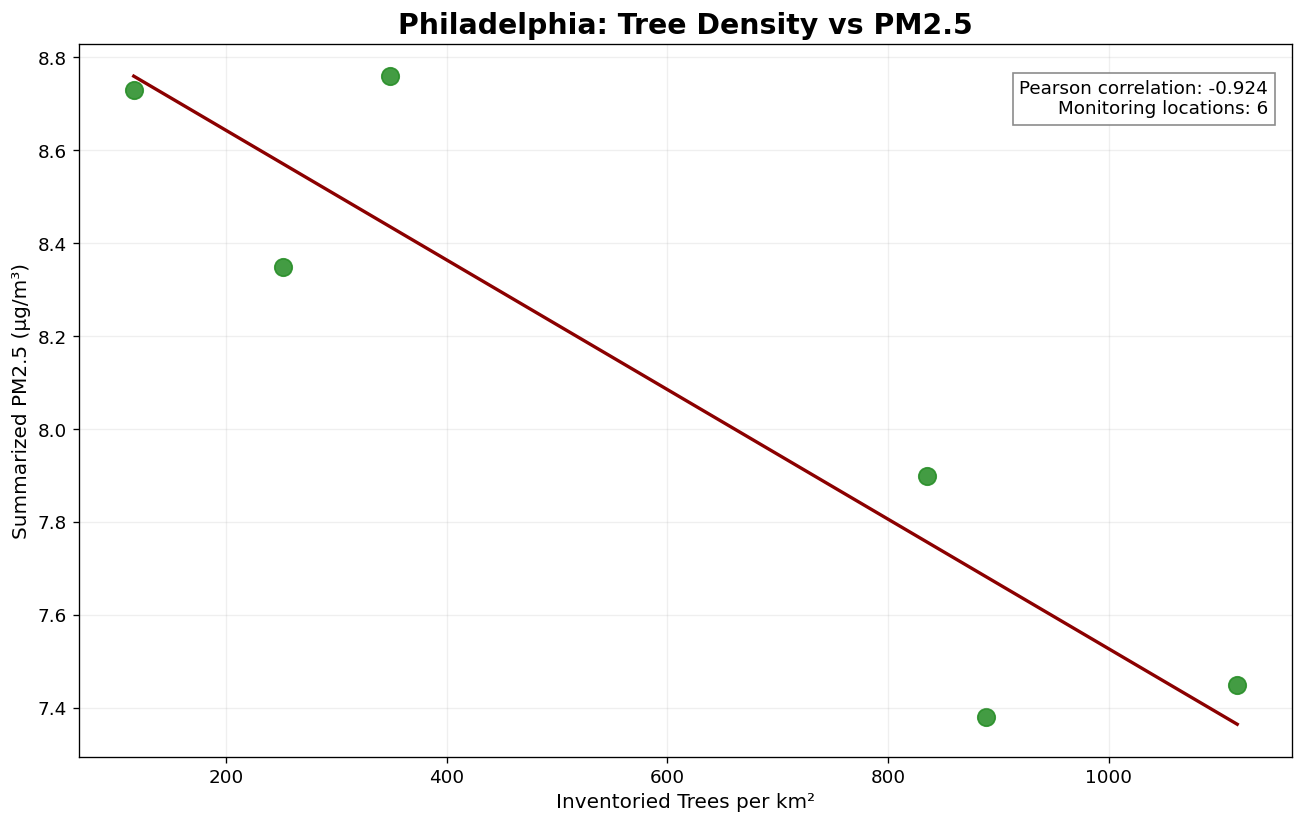

Tree Density and PM2.5 Analysis
Monitoring locations: 6
Pearson correlation: -0.9240
Pearson p-value: 0.008440
Note: Six stations provide limited statistical evidence.
Correlation does not establish causation.


In [26]:

# PS3 - Section 6.6: Tree Density vs PM2.5

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Prepare matched observations
pm25_analysis = pm25_tree_match[
    ["tree_density_km2", "pm25_mean"]
].dropna().copy()

# Calculate correlation
if len(pm25_analysis) >= 3:
    pearson_r, pearson_p = pearsonr(
        pm25_analysis["tree_density_km2"],
        pm25_analysis["pm25_mean"]
    )

    # Create scatter plot
    plt.figure(figsize=(11, 7))

    sns.regplot(
        data=pm25_analysis,
        x="tree_density_km2",
        y="pm25_mean",
        scatter_kws={
            "color": "forestgreen",
            "s": 110,
            "alpha": 0.85
        },
        line_kws={
            "color": "darkred",
            "linewidth": 2
        },
        ci=None
    )

    plt.title(
        "Philadelphia: Tree Density vs PM2.5",
        fontsize=17,
        fontweight="bold"
    )

    plt.xlabel(
        "Inventoried Trees per km²",
        fontsize=12
    )

    plt.ylabel(
        "Summarized PM2.5 (µg/m³)",
        fontsize=12
    )

    plt.text(
        0.98, 0.95,
        f"Pearson correlation: {pearson_r:.3f}\n"
        f"Monitoring locations: {len(pm25_analysis)}",
        transform=plt.gca().transAxes,
        ha="right",
        va="top",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    print("Tree Density and PM2.5 Analysis")
    print("=" * 45)
    print("Monitoring locations:", len(pm25_analysis))
    print(f"Pearson correlation: {pearson_r:.4f}")
    print(f"Pearson p-value: {pearson_p:.6f}")
    print("Note: Six stations provide limited statistical evidence.")
    print("Correlation does not establish causation.")

else:
    print("Insufficient matched observations for analysis.")

### 6.7 Interpretation of Tree Density and PM2.5 Results

In this part of my analysis, I compared tree density with PM2.5 air pollution using six EPA monitoring locations in Philadelphia.

The Pearson correlation was -0.924, which shows a strong negative relationship in the available data. This means that monitoring locations in census tracts with higher inventoried tree density generally had lower PM2.5 concentrations.

The p-value was 0.00844, which is below 0.05, indicating a statistically significant correlation under the standard Pearson test assumptions.

One important limitation is that I only have six monitoring locations. Because of this, I cannot assume the same relationship exists throughout Philadelphia. Other factors such as traffic, industrial activity, weather, and neighborhood conditions could also influence air pollution.

This analysis gives me an initial understanding of how urban greenery and air pollution may be related, but more monitoring locations and additional environmental data would be needed for stronger conclusions.

## 7. Final Findings and Conclusion

### 7.1 What I Found

In this project, I explored how Philadelphia's urban environment is related to public health, focusing on tree density, short sleep duration, and PM2.5 air pollution.

After cleaning and combining the datasets, I found a few interesting patterns:

- **Tree Density and Sleep:** Across 357 census tracts, I found a negative Pearson correlation of -0.388 between tree density and short sleep duration. This suggests that areas with more inventoried trees generally have lower estimates of insufficient sleep.

- **Sleep Health Differences:** The average estimated short sleep duration was approximately 41.9%. The maps also showed that sleep health is not equally distributed across Philadelphia neighborhoods.

- **Tree Density and Air Pollution:** Using six EPA monitoring locations, I found a strong negative correlation of -0.924 between tree density and PM2.5 concentrations. However, the small number of monitoring locations limits how confidently I can generalize this result.

### 7.2 Limitations

One limitation of my project is that the datasets do not all have the same geographic coverage. The sleep analysis included 357 census tracts, while the PM2.5 analysis included only six monitoring locations.

Also, these relationships are based on observational data. Factors such as income, traffic, housing conditions, and population characteristics may influence the results.

### 7.3 Conclusion

From this analysis, I learned that Philadelphia's environmental conditions and public health indicators show some meaningful geographic patterns.

The results suggest that neighborhoods with higher inventoried tree density tend to have lower short sleep duration estimates, while the limited air pollution data also shows a negative relationship with tree density.

These findings do not prove that trees directly improve sleep or reduce air pollution, but they provide useful starting points for further research.

In the future, I would like to include more environmental monitoring data and additional neighborhood-level health indicators to better understand these relationships.

### 7.4 AI Assistance and Acknowledgment

While working on this project, I used ChatGPT (OpenAI) as a supporting tool to help me understand some Python coding concepts, troubleshoot errors, and improve the organization of my Google Colab notebook.

I also used AI assistance to help structure parts of my data analysis, visualizations, and written explanations.

The project uses publicly available datasets, including Philadelphia tree inventory data, CDC PLACES health estimates, and EPA air quality monitoring data.

I reviewed the code outputs, visualizations, and statistical results in Google Colab and used them to develop my interpretation of the findings.

AI was used as a learning and development support tool, not as a source of environmental or public health data.